In [1]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
df = pd.read_csv("data/final_df.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 61 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   filename                 1000 non-null   object 
 1   length                   1000 non-null   int64  
 2   chroma_stft_mean         1000 non-null   float64
 3   chroma_stft_var          1000 non-null   float64
 4   rms_mean                 1000 non-null   float64
 5   rms_var                  1000 non-null   float64
 6   spectral_centroid_mean   1000 non-null   float64
 7   spectral_centroid_var    1000 non-null   float64
 8   spectral_bandwidth_mean  1000 non-null   float64
 9   spectral_bandwidth_var   1000 non-null   float64
 10  rolloff_mean             1000 non-null   float64
 11  rolloff_var              1000 non-null   float64
 12  zero_crossing_rate_mean  1000 non-null   float64
 13  zero_crossing_rate_var   1000 non-null   float64
 14  harmony_mean             

### Step 1: Load + Prep
- Separating X (fetaure columns) from y (genre label), will do ths twice for original dataset and one for condensed one derived form PCA loadings. Will need to encode them to be numerical than strings.

In [3]:
df1 = df.drop(columns = ["filename", "length", "label"])
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 58 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   chroma_stft_mean         1000 non-null   float64
 1   chroma_stft_var          1000 non-null   float64
 2   rms_mean                 1000 non-null   float64
 3   rms_var                  1000 non-null   float64
 4   spectral_centroid_mean   1000 non-null   float64
 5   spectral_centroid_var    1000 non-null   float64
 6   spectral_bandwidth_mean  1000 non-null   float64
 7   spectral_bandwidth_var   1000 non-null   float64
 8   rolloff_mean             1000 non-null   float64
 9   rolloff_var              1000 non-null   float64
 10  zero_crossing_rate_mean  1000 non-null   float64
 11  zero_crossing_rate_var   1000 non-null   float64
 12  harmony_mean             1000 non-null   float64
 13  harmony_var              1000 non-null   float64
 14  perceptr_mean            

In [4]:
X = df1.drop(columns = ["final_group"]) #feature cols
y = df1['final_group'] #genre label (pca derived one)
y_df = pd.DataFrame(y)
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_df['final_group_encoded'] = le.fit_transform(y_df['final_group'])
y_df.value_counts()

final_group  final_group_encoded
Rhythmic     2                      400
Acoustic     0                      300
Electric     1                      300
Name: count, dtype: int64

- stratify: The 3 classes aren't equal sizes, this will force the split to preserve the same class proprtions in both train and test. If a class is 30% of full data, it'll be 30% of train and 30% of test. 

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y_df['final_group_encoded'], test_size=0.2, stratify=y_df['final_group_encoded'], random_state=42)

- n_estimators = # of trees aka 300
- oob_score_true = compute out of bag score

In [6]:
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

,n_estimators,300
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,True


In [7]:
print(rf.score(X_test, y_test))
print(rf.oob_score_)

0.805
0.77


In [8]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nReport:\n", classification_report(y_test, y_pred, target_names=le.classes_))

Accuracy: 0.805

Confusion matrix:
 [[48  0 12]
 [ 2 47 11]
 [ 4 10 66]]

Report:
               precision    recall  f1-score   support

    Acoustic       0.89      0.80      0.84        60
    Electric       0.82      0.78      0.80        60
    Rhythmic       0.74      0.82      0.78        80

    accuracy                           0.81       200
   macro avg       0.82      0.80      0.81       200
weighted avg       0.81      0.81      0.81       200



## Random Forest — Notes & Gotchas (things I got confused on)

### Results
- Naive baseline (majority class): 55%
- KNN (tuned): 73%
- Random Forest — OOB: 77.3% | Test: 80.5%
- OOB ≈ Test (77.3 vs 80.5) → confirms OOB works like a free held-out validation set.

### 1. stratify in train_test_split
- My 3 classes are imbalanced (that's why baseline = 55%).
- `stratify=y` keeps the SAME class proportions in train and test.
- Without it, an unlucky split could over/under-represent a class and make accuracy misleading.

### 2. What OOB score actually is
- Split happens FIRST: 800 train / 200 test. Forest only sees the 800.
- Each of the 300 trees trains on a bootstrap sample (~63% of the 800);
  the ~37% left out are that tree's "out-of-bag" points.
- For each training point, ONLY the trees that didn't train on it vote → tally correct/wrong.
- OOB accuracy is computed over the 800 TRAINING points (~618/800 correct), NOT all 1000.
- The 200 test points are separate — scored by rf.score(X_test, y_test).
- Why it's great: validation estimate using only training data, no extra training. Bagging-only perk.

### 3. Metric mismatch — the big one
- Genre labels 0/1/2 are CATEGORIES, not a numeric scale.
- This is a CLASSIFICATION problem → use accuracy / confusion matrix / precision-recall-f1.
- MSE and R² are REGRESSION metrics (for predicting a continuous number). They ran without
  error but the numbers are MEANINGLESS here — wrong metrics fail silently.
- Rule: match the metric to the problem type myself; don't trust that "it ran" = "it's right".

### 5. Trees vs scaling
- Tree models split on thresholds → no feature scaling needed (unlike KNN, which needed it).

### Interview one-liners
- "I checked OOB error against held-out test accuracy and they matched (~77 vs 80%)."
- "With imbalanced classes, accuracy isn't enough — I read the confusion matrix and per-class
  recall to be sure I wasn't just winning on the majority class."

### Single Decision Tree - Visualization

Single tree train acc: 0.71375
Single tree test acc: 0.665


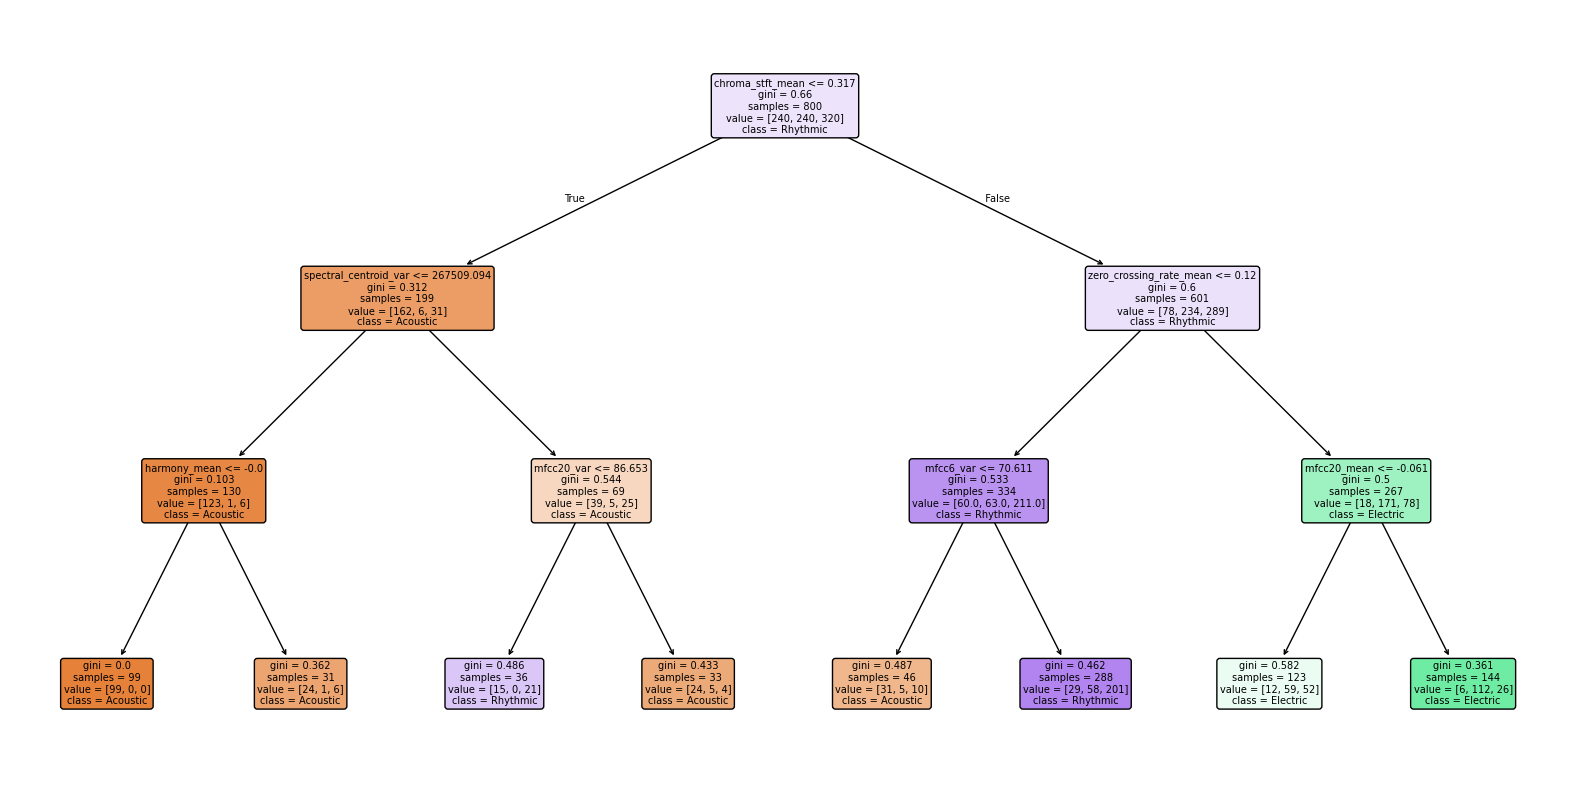

In [9]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

single = DecisionTreeClassifier(max_depth=3, random_state=42)   # cap depth so it's readable
single.fit(X_train, y_train)
print("Single tree train acc:", single.score(X_train, y_train))
print("Single tree test acc:", single.score(X_test, y_test))

plt.figure(figsize=(20, 10))
plot_tree(single, feature_names=X.columns, class_names=le.classes_,
          filled=True, rounded=True)
plt.show()

### Single decision tree with depth set to None for overfitting

Single tree train acc: 1.0
Single tree test acc: 0.68


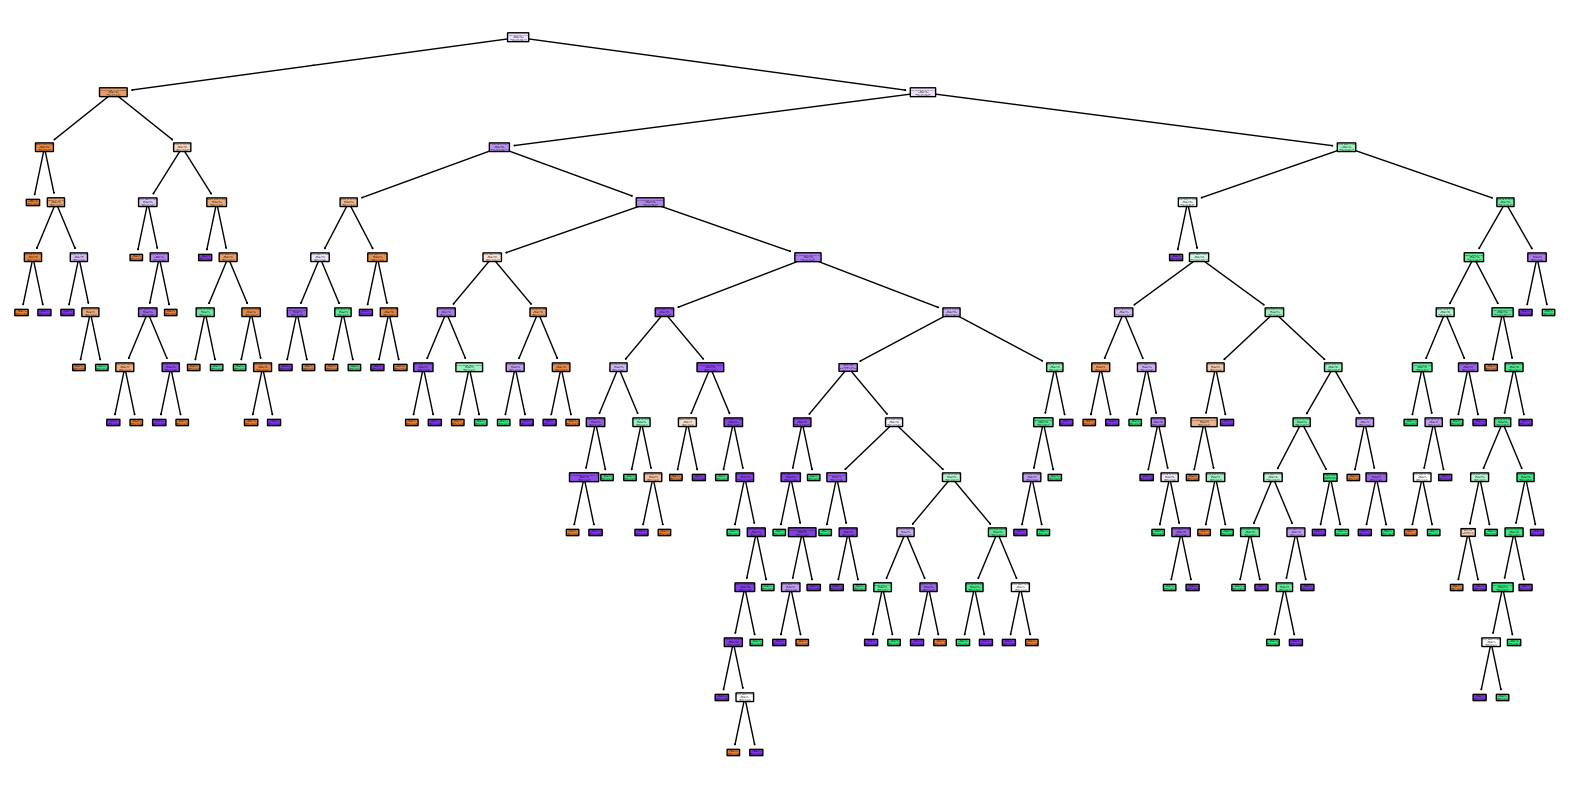

In [10]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

single = DecisionTreeClassifier(max_depth=None, random_state=42)   # when depth is none, it overfits
single.fit(X_train, y_train)
print("Single tree train acc:", single.score(X_train, y_train))
print("Single tree test acc:", single.score(X_test, y_test))

plt.figure(figsize=(20, 10))
plot_tree(single, feature_names=X.columns, class_names=le.classes_,
          filled=True, rounded=True)
plt.show()

Just Bagging without RF aspect:
- Random Forest = Bagging + random feature subsampling at each split. So there are two ingredients stacked together, and normally you only ever see them combined inside RandomForestClassifier. You can't tell how much each ingredient is contributing.
This experiment pulls them apart:

- BaggingClassifier builds many trees on bootstrap samples and averages them — but each tree is allowed to consider all features at every split. So it's bagging only, without the feature-subsampling decorrelation trick. (By default it wraps full decision trees.)
RandomForestClassifier does the same bootstrapping plus restricts each split to a random subset of features (sqrt by default) — the decorrelation ingredient.

- So by running both and comparing scores, you're measuring exactly how much the feature-subsampling ingredient adds on its own. That's what "isolation" means — you're isolating the one variable.
What to expect and how to read it:

- If RF > Bagging, the gap is the value of feature subsampling — the decorrelation is buying you accuracy. This is the payoff we discussed two rounds ago (the "sky color dominates every tree" problem — feature subsampling stops that, decorrelates the trees, lowers variance more).
If they're basically equal, that tells you something too: your dataset probably doesn't have one dominant feature hijacking every tree, so decorrelation has little to add here.

- Either result is informative — you're not hoping for one, you're measuring which world your data lives in.

In [10]:
from sklearn.ensemble import BaggingClassifier
bag = BaggingClassifier(n_estimators=300, oob_score=True, random_state=42, n_jobs=-1)
bag.fit(X_train, y_train)
print("Bagging OOB:", bag.oob_score_)   # bagging WITHOUT feature subsampling
print(bag.score(X_test, y_test))

Bagging OOB: 0.76125
0.79


In [11]:
from sklearn.model_selection import GridSearchCV
# 3x3x2x3 = 54 combos x 5 folds = 270 fits
param_grid = {
    'n_estimators':     [100, 300, 500],
    'max_depth':        [None, 2, 3, 4],
    'max_features':     ['sqrt', 'log2'],
    'min_samples_leaf': [1, 2, 4],
}

grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1), #-1 means use all cores
    param_grid=param_grid,
    cv=5,                    # 5-fold cross-validation
    scoring='f1_macro',      # optimize for the metric that catches minority classes
    n_jobs=-1,
    verbose=1,
)

grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV score:", grid.best_score_)

rf_tuned = grid.best_estimator_        # the refit model with the winning settings
print("Test accuracy:", rf_tuned.score(X_test, y_test))

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best params: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}
Best CV score: 0.7863376289957874
Test accuracy: 0.81


- Random Forest works by creating many decision trees on a bootstrapped sample of the data. So if we have a test and train set, from the train we bootstrap 300 times and each iteration has a tree generated but the special thing about rf is that we choose a subset of the features it can split on at each given node allowing us to give importance or equal chance to all the features and observe which ones reduce the impurity metric.
- Feature subsampling happens at each split, not once per tree: Example. Say you have 9 audio features and max_features='sqrt' → 3 features per split. For one tree:

* Root node: RF randomly offers it {mfcc4, tempo, zero_crossing}. It picks the best of those 3 to split on — say mfcc4.
Next node down: RF draws a new random 3, say {spectral_centroid, mfcc4, rolloff}. Picks the best of those.
Node after that: another fresh 3, say {chroma, tempo, mfcc9}.

* So even within a single tree, different nodes see different candidate features. That's what makes the decorrelation so effective — a dominant feature can't hog every split, because at many nodes it simply isn't in the offered subset.

 or provide us teh highest information gain. 
 - Then we average across each tree per feature an feature importance i sgnerated as a byproduct.
 -  It is also important to note that rf is only used when we have a ground truth label aka supervised learning

In [15]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.head(15))

chroma_stft_mean           0.073669
zero_crossing_rate_mean    0.044023
rolloff_mean               0.041274
mfcc1_mean                 0.040996
spectral_centroid_mean     0.038250
perceptr_var               0.037949
spectral_bandwidth_mean    0.031478
spectral_centroid_var      0.026569
mfcc5_var                  0.026340
mfcc20_mean                0.024607
mfcc4_mean                 0.020621
mfcc4_var                  0.020338
mfcc7_var                  0.019321
mfcc6_var                  0.019288
mfcc2_mean                 0.019121
dtype: float64


### Feature importance
- Machine learning models often act as black boxes, meaning that they can make good predictions but it is difficult to fully comprehend the decisions that drive those predictions.One of the most trivial queries regarding a model might be determining which features have the biggest impact on predictions, called feature importance. 

### MDI / feature_importances_

- Computed during training, as a free byproduct — no extra work.
- Measures total impurity decrease (gini/entropy) each feature produced across all splits, averaged over all trees.
- RF-specific — only exists for tree models that track impurity.
- Biased toward high-cardinality features (many unique values, e.g. continuous or ID-like columns) because they offer more places to split, so they rack up more impurity-decrease opportunities even when not truly predictive.
- Reflects what the model learned to rely on during training — can be inflated by overfitting to noise.

### Permutation importance
- Computed after training, on a held-out set (test or validation).
Works by shuffling one feature's values and measuring how much accuracy (or your chosen metric) drops. Big drop = model really depended on it; no drop = it didn't matter. Your "reverse-engineering" intuition is exactly right.
- Model-agnostic — works on any trained model (RF, XGBoost, SVM, neural net), not just trees.
- Not fooled by cardinality — it measures real predictive contribution, because shuffling a useless-but-high-cardinality column won't hurt accuracy.
- Reflects what the model actually uses to generalize on unseen data, not just what it memorized in training.
- Cost: slower (re-scores the model once per feature), and results vary slightly run-to-run because shuffling is random.

* Where they agree, you trust the feature. Where MDI ranks a feature high but permutation ranks it low, that's the tell-tale sign of the cardinality bias — MDI was fooled, permutation caught it.

### Boosting
- AdaBoost
- GradientBoosting
- XGBoost
* Code is very simple: split, instantiate, fit, predict, evaluate. And the metric question is the same lesson from before: this is still classification (predicting a genre category), so use accuracy / F1, NOT R² or MSE.Those are regression metrics. 
- unlike random forests — where more trees never hurt (they just plateau) — boosting can eventually overfit if you add too many estimator


In [11]:
# AdaBoost
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=300,
    learning_rate=0.5,
    random_state=42,
)
ada.fit(X_train, y_train)
y_pred = ada.predict(X_test)

from sklearn.metrics import accuracy_score, f1_score, classification_report
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average='macro'))
print(classification_report(y_test, y_pred, target_names=le.classes_))

Accuracy: 0.735
Macro F1: 0.738217957497138
              precision    recall  f1-score   support

    Acoustic       0.81      0.72      0.76        60
    Electric       0.72      0.77      0.74        60
    Rhythmic       0.70      0.72      0.71        80

    accuracy                           0.73       200
   macro avg       0.74      0.74      0.74       200
weighted avg       0.74      0.73      0.74       200



staged_predict gives the ensemble's prediction after 1 stump, 2 stumps, … up to 200 — giving whole accuracy-vs-stumps curve from a single trained model. to see where does it flatten? Is 50 basically as good as 200? Does it peak and then droop (overfitting)

C:\Users\sonuk\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(


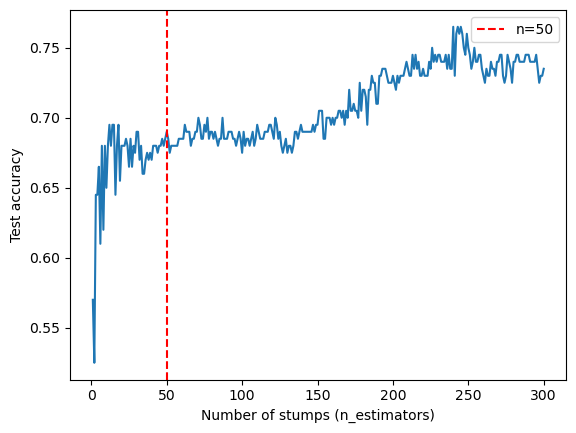

Best accuracy: 0.765 at n = 240


In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

test_scores = [accuracy_score(y_test, pred) for pred in ada.staged_predict(X_test)]

plt.plot(range(1, len(test_scores)+1), test_scores)
plt.xlabel("Number of stumps (n_estimators)")
plt.ylabel("Test accuracy")
plt.axvline(50, color='r', ls='--', label='n=50')
plt.legend(); plt.show()

print("Best accuracy:", max(test_scores), "at n =", test_scores.index(max(test_scores))+1)

In [13]:
from sklearn.ensemble import GradientBoostingClassifier

gbc = GradientBoostingClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,          # shallow trees = weak learners (not stumps, but small)
    random_state=42,
    max_features=4,
)
gbc.fit(X_train, y_train)
y_pred = gbc.predict(X_test)

from sklearn.metrics import accuracy_score, f1_score, classification_report
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average='macro'))
print(classification_report(y_test, y_pred, target_names=le.classes_))

Accuracy: 0.835
Macro F1: 0.8378683246533752
              precision    recall  f1-score   support

    Acoustic       0.91      0.87      0.89        60
    Electric       0.84      0.78      0.81        60
    Rhythmic       0.78      0.85      0.81        80

    accuracy                           0.83       200
   macro avg       0.84      0.83      0.84       200
weighted avg       0.84      0.83      0.84       200



In [15]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,           # use 80% of rows per tree (regularization)
    colsample_bytree=0.8,    # use 80% of features per tree (regularization)
    reg_lambda=1.0,          # L2 regularization on leaf weights
    random_state=42,
    eval_metric='mlogloss',
)
xgb.fit(X_train, y_train)
y_pred = xgb.predict(X_test)

from sklearn.metrics import accuracy_score, f1_score, classification_report
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average='macro'))
print(classification_report(y_test, y_pred, target_names=le.classes_))

Accuracy: 0.835
Macro F1: 0.8375615828987422
              precision    recall  f1-score   support

    Acoustic       0.91      0.87      0.89        60
    Electric       0.81      0.80      0.81        60
    Rhythmic       0.80      0.84      0.82        80

    accuracy                           0.83       200
   macro avg       0.84      0.83      0.84       200
weighted avg       0.84      0.83      0.84       200



In [16]:
importances = pd.Series(xgb.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.head(15))

chroma_stft_mean           0.078606
zero_crossing_rate_mean    0.070942
rolloff_mean               0.041332
spectral_centroid_var      0.038969
spectral_centroid_mean     0.037327
mfcc1_mean                 0.032400
mfcc5_var                  0.029884
mfcc6_var                  0.026379
chroma_stft_var            0.025346
mfcc20_mean                0.023639
mfcc19_var                 0.023508
spectral_bandwidth_mean    0.022595
mfcc4_var                  0.021035
perceptr_var               0.020558
mfcc18_var                 0.018631
dtype: float32


In [17]:
xgb.get_booster().get_score(importance_type='gain')

{'chroma_stft_mean': 10.08384895324707,
 'chroma_stft_var': 3.2514429092407227,
 'rms_mean': 1.6106996536254883,
 'rms_var': 1.9616574048995972,
 'spectral_centroid_mean': 4.788430213928223,
 'spectral_centroid_var': 4.999084949493408,
 'spectral_bandwidth_mean': 2.898512601852417,
 'spectral_bandwidth_var': 1.635535478591919,
 'rolloff_mean': 5.302247047424316,
 'rolloff_var': 2.261519193649292,
 'zero_crossing_rate_mean': 9.10071086883545,
 'zero_crossing_rate_var': 1.2899196147918701,
 'harmony_mean': 1.586800217628479,
 'harmony_var': 1.968178629875183,
 'perceptr_mean': 1.9837348461151123,
 'perceptr_var': 2.637308120727539,
 'tempo': 0.8955121040344238,
 'mfcc1_mean': 4.156441688537598,
 'mfcc1_var': 1.3104852437973022,
 'mfcc2_mean': 0.933530867099762,
 'mfcc2_var': 1.094870686531067,
 'mfcc3_mean': 1.0404877662658691,
 'mfcc3_var': 1.0299824476242065,
 'mfcc4_mean': 2.066679000854492,
 'mfcc4_var': 2.6984310150146484,
 'mfcc5_mean': 0.9696411490440369,
 'mfcc5_var': 3.833572864